#Smart Real Estate Price Analysis

##Project Domain:
- Properties Analytics
- Data Analytics
- Business Intelligence

##Project Objective:
- The objective of this project is to analyze housing market data to understand the major factors affecting property prices, handle missing values and data in real-world datasets, and use data visualization techniques to identify market trends and patterns. The project aims to support buyers, sellers, real-estate professionals, and investors.

##Skills:
- Python
- Pandas
- Numpy
- Data Cleaning & Preprocessing
- Missing Value Treatment.
- Exploratory Data Analysis(EDA)
- Data Visulization (Matplotlib & Seaborn)
- Business Insight Generation

##Datatset Information
- Dataset Name: King County House Sales Dataset (with missing values)
- Records: 21,613
- Features: 22
- Target Variable: price

##Key Attributes:
- Property Dimensions: Living area, lot size etc
- Building Structure: No of bedrooms, bathrooms, and floors.
- Property Quality: Construction quality, building condition.
- Location-Based Factors:Waterfront availability, and surrounding views.
- Construction and Renovation Details: Year built, year renovated etc

##Step 1:-Importing Data & Understanding

In [1]:
import pandas as pd
df=pd.read_csv("/content/kc_house_data_NaN.csv")
df.head()

,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [2]:
print("Shape:",df.shape)
print("Size:",df.size)
print("Dimension:",df.ndim)



Shape: (21613, 22)
Size: 475486
Dimension: 2


In [3]:
#Dataset Summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  object 
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int64  
 11  condition      21613 non-null  int64  
 12  grade          21613 non-null  int64  
 13  sqft_above     21613 non-null  int64  
 14  sqft_basement  21613 non-null  int64  
 15  yr_built       21613 non-null  int64  
 16  yr_renovated   21613 non-null  int64  
 17  zipcode        21613 non-null  int64  
 18  lat   

In [4]:
#Datataset Statistical Summary
df.describe()

,Unnamed: 0,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,21613.00000,2.161300e+04,2.161300e+04,21600.000000,21603.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,...,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,10806.00000,4.580302e+09,5.400881e+05,3.372870,2.115736,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,...,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,6239.28002,2.876566e+09,3.671272e+05,0.926657,0.768996,918.440897,4.142051e+04,0.539989,0.086517,0.766318,...,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,0.00000,1.000102e+06,7.500000e+04,1.000000,0.500000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,...,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,5403.00000,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,...,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,10806.00000,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,...,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,16209.00000,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,...,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,21612.00000,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,...,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


##Objectives:-
- Examine dataset to understand its structure and types.
- Classify the dataset attributes into numerical and categorical variables.
- Detect missing values.
-  Analyze statistics to understand data distribution, characteristics.

#Step 2: Data Cleaning Process

- Removing Unwanted columns.

In [5]:
#Droping irrelevent columns
df.drop(columns =['Unnamed: 0'], inplace= True)

- Missing  Data Detection

In [6]:
#Viewing Missing Values
df.isnull().sum()

,0
id,0
date,0
price,0
bedrooms,13
bathrooms,10
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [7]:
#Finding missing Percentage
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent

,0
id,0.000000
date,0.000000
price,0.000000
bedrooms,0.060149
bathrooms,0.046268
sqft_living,0.000000
sqft_lot,0.000000
floors,0.000000
waterfront,0.000000
view,0.000000


###Observations
Columns Missing:-
- Bedrooms
- Bathroom

##Missing Data Treatment

In [8]:
#Filling Missing Values
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].mean())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].mean())

In [9]:
df.isna().sum()

,0
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


###Data Formatting

In [10]:
# Converting values into Pandas Datetime Format.
df['date'] = pd.to_datetime(df['date'])

In [11]:
df['date'].dtype

dtype('<M8[ns]')

#Step 3: Exploratory Data Analysis (EDA)

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

##Q1.What is the distrubution of house prices?

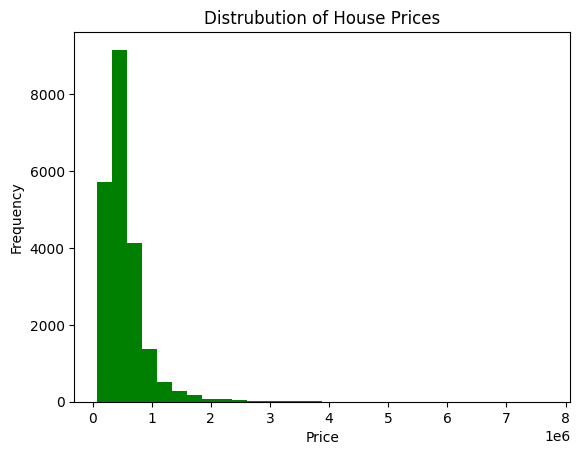

In [22]:
plt.figure()
plt.hist(df['price'], bins=30,color='green')
plt.title("Distrubution of House Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

###Analysis :-
- Most houses fall within the lower and middle price ranges.
- Distrubution is Right Skewed.

###Conclusion:
- Market mainly consists of affordable properties, with fewer luxury houses.


##Q2. How does living area affect price?

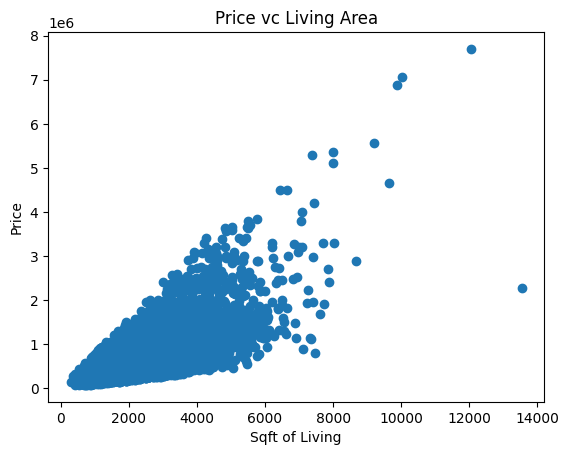

In [28]:
plt.scatter(df['sqft_living'], df['price'])
plt.xlabel("Sqft of Living")
plt.ylabel("Price")
plt.title("Price vc Living Area")
plt.show()

###Analysis:

- The graph shows a positive relationship between living area and house price

###Conclusion:

- Generally, houses with larger living areas have higher prices.

##Q3. What is the relationship between bedrooms and Price.

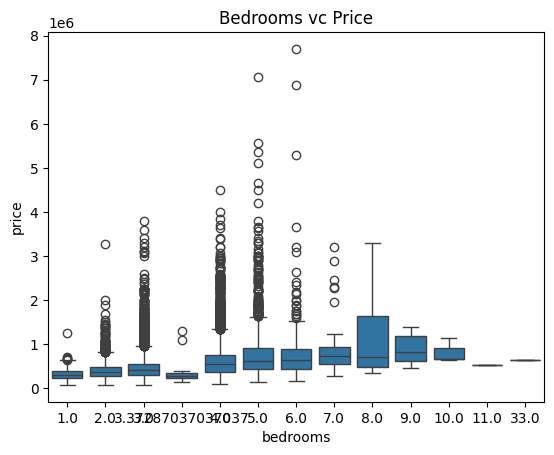

In [18]:
sns.boxplot(x = 'bedrooms', y='price', data=df)
plt.title("Bedrooms vc Price")
plt.show()

###Analysis:

- House prices generally increase with the number of bedrooms

###Conclusion:

- More bedrooms can increase a house's value, but it is not consistent.

##Q4. Do bathrooms impack house price?

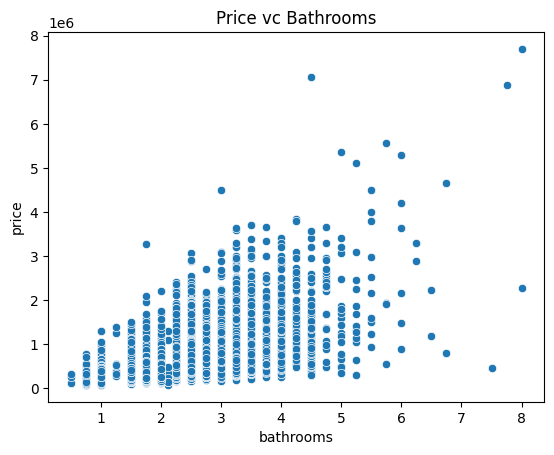

In [19]:
sns.scatterplot(x ='bathrooms', y ='price', data = df)
plt.title("Price vc Bathrooms")
plt.show()

###Analysis:

- Houses with more bathrooms have higher prices

###Conclusion:

- The number of bathrooms can influence house prices.

##Q5.Does waterfront view increase price?

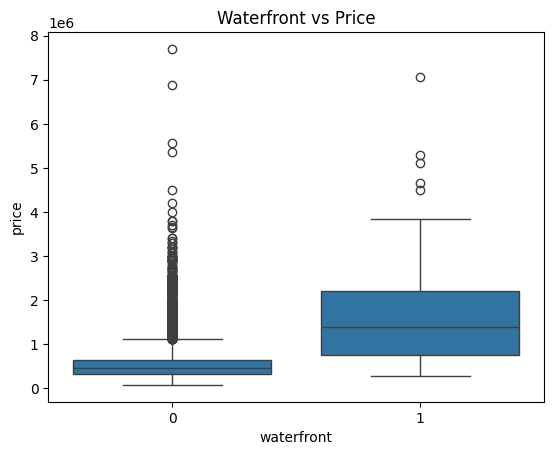

In [20]:
sns.boxplot(x='waterfront', y='price', data=df)
plt.title("Waterfront vs Price")
plt.show()

###Analysis:

Houses with waterfront generally have higher prices than houses without it.

###Conclusion:

Waterfront access is a premium feature.

##Q6.What is the correlation among key variables?

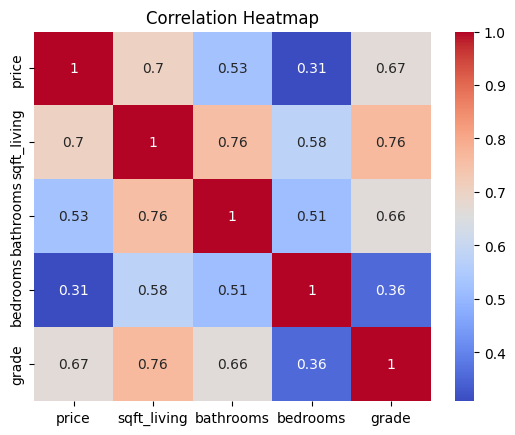

In [31]:
corr = df[['price','sqft_living','bathrooms','bedrooms','grade']].corr()
sns.heatmap(corr, annot=True,cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

###Analysis:

Living area shows the strongest correlation with house price.

###Conclusion:

Living area is an important factor for understanding house prices.

##Q7.Which features have the strongest correlation with house prices?

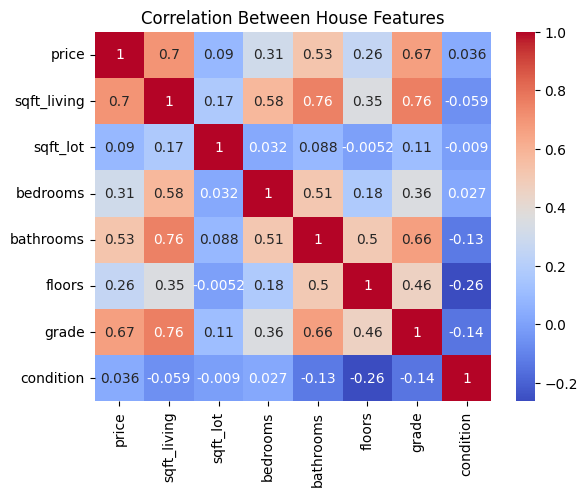

In [32]:
corr = df[['price', 'sqft_living', 'sqft_lot','bedrooms', 'bathrooms', 'floors', 'grade', 'condition']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Between House Features")
plt.show()

###Analysis:
- Living area and house grade show a strong positive relationship with house prices

###Conclusion:
- Larger houses with better construction grades generally have higher prices

#Step 4: Data Visualization Dashboard

###Key Business Insights (Analytics Outcome)
- Larger living areas generally lead to higher house prices.
- Bathrooms can affect prices more than the number of bedrooms.
- Better construction quality and grade increase property value.
- Waterfront, good views, and renovation can make houses more premium.

##Final Conclusion
- This project succesfully helped in cleaning and organizing real-estate data by handling missing values and improving data quality.
- This analysis showed key factors affecting house prices and provided useful insights to help buyers and real-estate businesses make better decisions.